# Lecture 5 participant notebook: Build a physical SO(3) ENN

This notebook trains the full spherical CG network on a dipole-inspired nonlinear response. The
training set covers all relative angles but only a narrow band of global orientations.

The finite-difference training cell may take roughly 10-30 seconds depending on hardware.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def random_rotation(rng):
    """Return a random proper 3D rotation using a unit quaternion."""
    q = rng.normal(size=4)
    q /= np.linalg.norm(q)
    w, x, y, z = q
    return np.array([
        [1-2*(y*y+z*z), 2*(x*y-z*w),   2*(x*z+y*w)],
        [2*(x*y+z*w),   1-2*(x*x+z*z), 2*(y*z-x*w)],
        [2*(x*z-y*w),   2*(y*z+x*w),   1-2*(x*x+y*y)],
    ])

In [2]:
# Spherical basis and Wigner D matrices
# Shared setup, identical in Lectures 2-5. Lecture 2 walks through it line by
# line; in later lectures just run it and move on.
from sympy.physics.wigner import clebsch_gordan  # Load tabulated CG coefficients from SymPy.

SQ2 = np.sqrt(2.0)  # Store sqrt(2), which appears repeatedly in the spherical basis.
U1 = np.array([  # Define the unitary change of basis from Cartesian (x,y,z) to m=(-1,0,+1).
    [1/SQ2, -1j/SQ2, 0],   # m=-1: v_-1 = (v_x - i v_y)/sqrt(2).
    [0,      0,       1],   # m= 0: v_0  = v_z.
    [-1/SQ2, -1j/SQ2, 0],  # m=+1: v_+1 = -(v_x + i v_y)/sqrt(2).
], dtype=complex)  # Spherical components are complex even for a real Cartesian vector.

def cart_to_sph(v):
    """Convert Cartesian vectors to spherical l=1 components.

    Inputs
    ------
    v : array, shape (..., 3)
        Real or complex vectors whose final axis is ordered (x, y, z).

    Returns
    -------
    array, shape (..., 3)
        Complex spherical components ordered by m=(-1, 0, +1).
    """
    v = np.asarray(v)  # Accept a list or ndarray and preserve any leading batch axes.
    return v @ U1.T  # Apply U1 to the final axis; row-vector storage requires the transpose.

def sph_to_cart(v_sph):
    """Convert spherical l=1 components back to Cartesian vectors.

    Inputs
    ------
    v_sph : array, shape (..., 3)
        Spherical components ordered by m=(-1, 0, +1).

    Returns
    -------
    array, shape (..., 3)
        Cartesian components ordered (x, y, z); physical real vectors become real arrays.
    """
    v_sph = np.asarray(v_sph)  # Accept a list or ndarray and preserve leading axes.
    v_cart = v_sph @ U1.conj()  # Apply U1^dagger; row-vector storage gives U1.conjugate().
    return np.real_if_close(v_cart, tol=1000)  # Remove round-off-sized imaginary parts only.

def cg_tensor(l1, l2, L):
    """Load one Clebsch-Gordan coupling tensor in the spherical basis.

    Inputs
    ------
    l1, l2 : int
        Angular momenta of the two input irreps.
    L : int
        Angular momentum of the coupled output irrep.

    Returns
    -------
    C : complex array, shape (2*L+1, 2*l1+1, 2*l2+1)
        C[M+L,m1+l1,m2+l2] equals <l1 m1,l2 m2 | L M>, including the
        fixed phase that preserves the reality convention for physical tensors.
    """
    C = np.zeros((2*L+1, 2*l1+1, 2*l2+1), dtype=complex)  # Allocate axes (M,m1,m2).
    for M in range(-L, L+1):  # Visit each output magnetic index M=-L,...,+L.
        for m1 in range(-l1, l1+1):  # Visit each magnetic index of the first input.
            m2 = M - m1  # The selection rule M=m1+m2 fixes the second magnetic index.
            if -l2 <= m2 <= l2:  # Skip combinations outside the second irrep's valid range.
                coefficient = clebsch_gordan(l1, l2, L, m1, m2, M)  # Ask SymPy for the CGC.
                C[M+L, m1+l1, m2+l2] = float(coefficient)  # Store it using zero-based indices.
    reality_phase = (-1j)**(l1+l2-L)  # Choose the phase making real inputs map to real tensors.
    return reality_phase * C  # Return fixed representation data, not a learnable parameter.

L_MAX = 2  # Highest irrep this course carries. This is a budget choice, NOT a symmetry
           # rule: the triangle rule genuinely allows 1x2->3 and 2x2->3,4, and we simply
           # do not build them. Raise L_MAX to get them, at rising cost.

CG = {}  # Map every allowed key (l1,l2,L) to its fixed Clebsch-Gordan tensor.
for l1 in range(L_MAX+1):  # Include first-input irreps l1=0,...,L_MAX.
    for l2 in range(l1, L_MAX+1):  # Store only l1<=l2; cg_product handles the reversed order.
        for L in range(abs(l1-l2), min(l1+l2, L_MAX)+1):  # Triangle rule, then truncate at L_MAX.
            CG[(l1, l2, L)] = cg_tensor(l1, l2, L)  # Load this coupling from SymPy once.

def D_sph(l, R):
    """Construct the Wigner D matrix for a 3D rotation.

    Inputs
    ------
    l : int
        Irrep degree; this compact example supports l=0,1,2.
    R : array, shape (3, 3)
        Active Cartesian rotation matrix acting as v_rotated = R @ v.

    Returns
    -------
    D : complex array, shape (2*l+1, 2*l+1)
        Wigner D^l(R), acting on m=-l,...,+l spherical components.
    """
    if l == 0:  # A scalar has one component and is unchanged by every rotation.
        return np.ones((1, 1), dtype=complex)  # D^0(R)=1.
    R = np.asarray(R)  # Normalize the input to an ndarray before matrix multiplication.
    D1 = U1 @ R @ U1.conj().T  # Rewrite the Cartesian rotation in the spherical l=1 basis.
    if l == 1:  # A spherical vector transforms directly with this 3x3 matrix.
        return D1  # Return D^1(R).
    if l == 2:  # Build the five-dimensional irrep from the 1 tensor 1 -> 2 coupling.
        C112 = CG[(1, 1, 2)]  # Fetch the fixed CG tensor selecting total angular momentum L=2.
        return np.einsum('Mab,ai,bj,Nij->MN', C112, D1, D1, C112.conj())  # C (D1 x D1) C^dagger;
        # the conjugate matters: C(1,1,2) happens to be real, but a coupling whose
        # phase (-i)^(l1+l2-L) is odd is not, and C^T would then be the wrong matrix.
    raise ValueError("this compact example implements l=0,1,2")  # Reject unsupported irreps.

def rotate_sph_features(features, R):
    """Rotate every multiplet in a feature dictionary.

    Inputs
    ------
    features : dict[int, array(batch, channels, 2*l+1)]
        Spherical features grouped by irrep degree l.
    R : array, shape (3, 3)
        Cartesian rotation applied to every sample and channel.

    Returns
    -------
    dict[int, array(batch, channels, 2*l+1)]
        A new dictionary with D^l(R) applied along every magnetic-index axis.
    """
    rotated = {}  # Create a new dictionary so the input features are not modified.
    for l, values in features.items():  # Process each irrep block independently.
        Dl = D_sph(l, R)  # Obtain the correct generalized rotation for this l.
        rotated[l] = np.einsum('mn,bcn->bcm', Dl, values)  # Contract D's input m with the feature m.
    return rotated  # Return all rotated irrep blocks.

v_cart = rng.normal(size=(5, 3))  # Draw five real Cartesian vectors for a round-trip test.
v_reconstructed = sph_to_cart(cart_to_sph(v_cart))  # Convert Cartesian -> spherical -> Cartesian.
roundtrip_error = np.max(np.abs(v_reconstructed - v_cart))  # Compare reconstruction to the original.
print(f"Cartesian <-> spherical round-trip: {roundtrip_error:.1e}")  # Expect floating-point error.

Ra = random_rotation(rng)  # Draw the first rotation used in the representation-law check.
Rb = random_rotation(rng)  # Draw the second rotation used in the representation-law check.
for l in (0, 1, 2):  # Test every irrep implemented in this example.
    hom = np.max(np.abs(D_sph(l, Ra) @ D_sph(l, Rb) - D_sph(l, Ra @ Rb)))  # Check D(Ra)D(Rb)=D(RaRb).
    unit = np.max(np.abs(D_sph(l, Ra) @ D_sph(l, Ra).conj().T - np.eye(2*l+1)))  # Check D D^dagger=I.
    print(f"l={l}: representation {hom:.1e}, unitary {unit:.1e}")  # Both errors should be near 1e-15.

Cartesian <-> spherical round-trip: 2.2e-16
l=0: representation 0.0e+00, unitary 0.0e+00
l=1: representation 2.2e-16, unitary 1.2e-16
l=2: representation 3.3e-16, unitary 2.2e-16


In [3]:
# Verify that each CG tensor is an equivariant map (Same as Lecture 4)
def cg_product(x, y, l1, l2, L):
    """Couple two spherical multiplets into total angular momentum L.

    Inputs
    ------
    x : array, shape (..., 2*l1+1)
        First spherical feature, ordered by m1=-l1,...,+l1.
    y : array, shape (..., 2*l2+1)
        Second spherical feature, ordered by m2=-l2,...,+l2.
    l1, l2 : int
        Irrep degrees of x and y.
    L : int
        Requested output irrep, satisfying |l1-l2| <= L <= l1+l2.

    Returns
    -------
    array, shape (..., 2*L+1)
        Coupled spherical feature ordered by M=-L,...,+L.
    """
    if l1 <= l2:  # CG stores only keys with the smaller irrep first.
        key = (l1, l2, L)  # Use the stored order directly.
        swap = False  # The tensor's m axes already match x and y.
    else:  # Reverse the lookup order when l1>l2.
        key = (l2, l1, L)  # Look up the canonical stored key.
        swap = True  # Record that the two input axes must be exchanged.
    C = CG[key]  # Fetch the fixed Clebsch-Gordan tensor.
    if swap:  # Align the tensor axes with the actual x,y order.
        # Exchanging the two irreps is not just an axis swap; it costs a sign, because
        # <l1 m1, l2 m2 | L M> = (-1)^(l1+l2-L) <l2 m2, l1 m1 | L M>.
        C = C.swapaxes(1, 2) * (-1.0)**(l1+l2-L)  # Swap the m axes and apply that sign.
    return np.einsum('Mij,...i,...j->...M', C, x, y)  # Sum C[M,m1,m2]x[m1]y[m2].

R = random_rotation(rng)  # Use one common rotation for all CG equivariance tests.
paths = [(1,1,0), (1,1,1), (1,1,2), (1,2,1), (2,2,2)]  # Select representative legal couplings.
print("  path       max |CG(Dx,Dy)-D CG(x,y)|")  # Label the residual printed below.
for l1, l2, L in paths:  # Test one input/output irrep combination at a time.
    x = rng.normal(size=2*l1+1) + 1j*rng.normal(size=2*l1+1)  # Draw a generic complex l1 multiplet.
    y = rng.normal(size=2*l2+1) + 1j*rng.normal(size=2*l2+1)  # Draw a generic complex l2 multiplet.
    x_rot = D_sph(l1, R) @ x  # Rotate x using the Wigner matrix for l1.
    y_rot = D_sph(l2, R) @ y  # Rotate y using the Wigner matrix for l2.
    lhs = cg_product(x_rot, y_rot, l1, l2, L)  # Route 1: rotate inputs, then couple them.
    coupled = cg_product(x, y, l1, l2, L)  # Couple the original inputs into an L multiplet.
    rhs = D_sph(L, R) @ coupled  # Route 2: couple first, then rotate the output.
    residual = np.max(np.abs(lhs-rhs))  # Equivariance requires the two routes to agree.
    print(f" {l1} x {l2} -> {L}              {residual:.1e}")  # Expect about machine precision.

  path       max |CG(Dx,Dy)-D CG(x,y)|
 1 x 1 -> 0              0.0e+00
 1 x 1 -> 1              1.5e-16
 1 x 1 -> 2              9.9e-16
 1 x 2 -> 1              6.2e-16
 2 x 2 -> 2              5.0e-16


In [6]:
# Equivariant tensor-product network (Same as Lecture 4)
def allowed(l1, l2, L):
    """Return whether l1 tensor l2 contains output irrep L.

    Inputs: integer angular momenta l1, l2, and L.
    Returns: bool implementing the SO(3) triangle rule.
    """
    return abs(l1-l2) <= L <= l1+l2  # SO(3) permits exactly this range of total angular momenta.

def layer_spec(mult_in, mult_out):
    """Describe every learnable weight array in one equivariant layer.

    Inputs
    ------
    mult_in, mult_out : dict[int, int]
        Number of input/output channels (multiplicities) for each irrep l.

    Returns
    -------
    spec : dict[tuple, tuple]
        Maps each linear or tensor-product path to its learnable weight shape.
    """
    spec = {}  # Collect parameter names and shapes without allocating their values yet.
    
    shared_irreps = sorted(set(mult_in) & set(mult_out))  # Find l values present at input and output.
    for l in shared_irreps:  # Add an equivariant linear path within each shared irrep.
        spec[('lin', l)] = (mult_out[l], mult_in[l])  # Mix channels while leaving the m axis untouched.
        
    for l1 in sorted(mult_in):  # Choose the first irrep entering a bilinear CG product.
        for l2 in sorted(mult_in):  # Choose the second irrep entering that product.
            if l2 < l1:  # Avoid listing the same unordered irrep pair twice.
                continue  # The l2<l1 version is represented through the canonical order.
            for L in sorted(mult_out):  # Consider each requested output irrep.
                if allowed(l1, l2, L) and max(l1, l2, L) <= 2:  # Keep legal paths supported here.
                    n_pairs = mult_in[l1] * mult_in[l2]  # Count all pairs of input channels.
                    spec[('tp', l1, l2, L)] = (mult_out[L], n_pairs)  # Learn how to mix path channels.
    return spec  # This dictionary completely specifies the layer's trainable architecture.

def layer_forward(params, features, mult_out, cgs=CG):
    """Apply equivariant linear and CG tensor-product paths.

    Inputs
    ------
    params : dict[tuple, array]
        Learnable channel-mixing matrices produced from layer_spec.
    features : dict[int, array(batch, channels, 2*l+1)]
        Input spherical features grouped by irrep degree.
    mult_out : dict[int, int]
        Requested output channel count for every output irrep.
    cgs : dict, optional
        Fixed CG tensors; injectable only so Section 6.4 can deliberately corrupt one.

    Returns
    -------
    out : dict[int, complex array(batch, channels_out, 2*l+1)]
        Output spherical feature multiplets.
    """
    batch = next(iter(features.values())).shape[0]  # Read the common batch size from any irrep block.
    out = {}  # Allocate one accumulator for every requested output irrep.
    
    for l, channels in mult_out.items():  # Visit each output type and its multiplicity.
        out[l] = np.zeros((batch, channels, 2*l+1), dtype=complex)  # Axes are (batch,channel,m).
        
    for key, weights in params.items():  # Accumulate the contribution of every allowed path.
        if key[0] == 'lin':  # This path mixes channels inside a single irrep.
            l = key[1]  # Read which irrep the linear path acts on.
            out[l] += np.einsum('oc,bcm->bom', weights, features[l])  # Contract channels, preserve m.
        else:  # This path couples two irreps through a fixed CG tensor.
            _, l1, l2, L = key  # Decode the input and output angular momenta from the key.
            C = cgs[(l1, l2, L)]  # Fetch C[M,m1,m2] for this coupling.
            products = np.einsum('Mij,bci,bdj->bcdM', C, features[l1], features[l2])  # Apply CG to m axes.
            products = products.reshape(batch, -1, 2*L+1)  # Flatten the two input-channel axes.
            out[L] += np.einsum('op,bpM->boM', weights, products)  # Learnably mix products, preserve M.
    return out  # Return all output irreps after summing their legal paths.

def gate_spec(mult, use_norms=False):
    """Specify parameters for invariant scalar nonlinearities and gates.

    Inputs: mult, a dict mapping each l to its channel count; use_norms, whether the gate
    may also see the squared norm of each l>0 channel.
    Returns: shapes for scalar biases and the gate's weight matrix and bias.
    """
    n_gates = sum(channels for l, channels in mult.items() if l > 0)  # One gate per non-scalar channel.
    n_inv = mult[0] + (n_gates if use_norms else 0)  # What the gate is allowed to look at.
    return {'b0': (mult[0],), 'Wg': (n_gates, n_inv), 'bg': (n_gates,)}  # Declare all gate parameters.

def gate_forward(params, features, mult, use_norms=False):
    """Apply symmetry-safe nonlinearities to a feature dictionary.

    Inputs
    ------
    params : dict[str, array]
        Scalar biases b0 plus gate weights Wg and gate biases bg.
    features : dict[int, array(batch, channels, 2*l+1)]
        Spherical features containing an l=0 block.
    mult : dict[int, int]
        Channel counts for the feature dictionary.
    use_norms : bool
        If True the gate also sees ||x||^2 for every l>0 channel, which is invariant because
        D^(l) is unitary. Must match the flag passed to gate_spec.

    Returns
    -------
    gated : dict with the same shapes as features
        Scalars pass through tanh; each l>0 multiplet is scaled uniformly over m.
    """
    scalars = features[0][:, :, 0].real  # Extract invariant l=0 values with shape (batch,channels_0).
    scalar_output = np.tanh(features[0].real + params['b0'][None, :, None])  # Nonlinearity is safe on l=0.
    gated = {0: scalar_output.astype(complex)}  # Keep a uniform complex dtype across irrep blocks.
    
    invariants = scalars  # The l=0 block is invariant by construction.
    if use_norms:  # Optionally widen what the gate may depend on.
        norms = np.concatenate([np.sum(np.abs(features[l])**2, axis=2)  # ||x||^2 per l>0 channel,
                                for l in sorted(mult) if l > 0], axis=1)  # invariant and free to form.
        invariants = np.concatenate([scalars, norms], axis=1)  # Same channel order as gate_spec.
    gate_logits = np.einsum('oc,bc->bo', params['Wg'], invariants) + params['bg']  # Map invariants to gates.
    gates = np.tanh(gate_logits)  # tanh(w . invariants + b): a learned affine map

    offset = 0  # Track which gate columns belong to the current non-scalar irrep.
    for l in sorted(mult):  # Visit irrep blocks in the same order used by gate_spec.
        if l == 0:  # The scalar block was handled separately above.
            continue  # Do not gate it a second time.
        width = mult[l]  # Read how many channels this irrep owns.
        block_gates = gates[:, offset:offset+width, None]  # Add a singleton m axis for broadcasting.
        gated[l] = features[l] * block_gates  # Scale every m component of a channel by one invariant.
        offset += width  # Advance to the gates for the next irrep block.
    return gated  # Return nonlinear features without violating equivariance.

M_IN = {1: 2}  # Input: two l=1 channels, representing vectors u and v.
M_HID = {0: 2, 1: 2, 2: 2}  # Hidden state: two channels each of scalars, vectors, and quadrupoles.
M_OUT = {1: 1}  # Output: one l=1 channel, representing the predicted vector.
SPECS = [layer_spec(M_IN, M_HID), gate_spec(M_HID), layer_spec(M_HID, M_OUT)]  # Describe layer, gate, layer.

def init_params(specs, rng, scale=0.4):
    """Initialize real learnable channel weights.

    Inputs: specs from layer_spec/gate_spec, NumPy RNG, and Gaussian scale.
    Returns: list of parameter dictionaries matching the supplied specs.
    """
    params = []  # Build one parameter dictionary for each architecture block.
    for spec in specs:  # Initialize blocks in forward-pass order.
        block = {}  # Hold every array belonging to this block.
        for key, shape in spec.items():  # Visit each named parameter and its requested shape.
            block[key] = rng.normal(size=shape) * scale  # Draw independent real Gaussian weights.
        params.append(block)  # Keep this initialized block.
    return params  # Return [first_layer, gate, second_layer] parameters.

def flatten(params):
    """Flatten a list of parameter dictionaries into one optimization vector.

    Input: params, a list of dictionaries of ndarrays.
    Returns: one-dimensional ndarray containing all entries in stable insertion order.
    """
    arrays = [weights.ravel() for block in params for weights in block.values()]  # Flatten each array.
    return np.concatenate(arrays)  # Join them into one vector for finite-difference optimization.

def unflatten(theta, specs):
    """Reconstruct structured parameter dictionaries from a flat vector.

    Inputs: theta, shape (n_parameters,), and the original list of shape specs.
    Returns: parameter dictionaries with the same structure produced by init_params.
    """
    params = []  # Accumulate reconstructed blocks.
    offset = 0  # Mark the first unread entry in theta.
    for spec in specs:  # Reconstruct blocks in the same order used by flatten.
        block = {}  # Hold the arrays for this block.
        for key, shape in spec.items():  # Reconstruct each parameter in insertion order.
            size = int(np.prod(shape))  # Count how many flat entries this array requires.
            block[key] = theta[offset:offset+size].reshape(shape)  # Slice and restore its shape.
            offset += size  # Advance past the entries just consumed.
        params.append(block)  # Keep the reconstructed block.
    return params  # Return structured parameters for the forward pass.

def net_sph(theta, U, V, cgs=CG):
    """Run the network and return its spherical l=1 output.

    Inputs: flat parameters theta; Cartesian batches U,V of shape (batch,3); fixed CG dictionary.
    Returns: complex array (batch,3), ordered by output m=(-1,0,+1).
    """
    first_params, gate_params, second_params = unflatten(theta, SPECS)  # Restore all parameter blocks.
    U_sph = cart_to_sph(U)  # Convert the first Cartesian input vector batch to spherical components.
    V_sph = cart_to_sph(V)  # Convert the second Cartesian input vector batch to spherical components.
    inputs = {1: np.stack([U_sph, V_sph], axis=1)}  # Form shape (batch,2 channels,3 m components).
    hidden_linear = layer_forward(first_params, inputs, M_HID, cgs)  # Produce l=0,1,2 hidden features.
    hidden = gate_forward(gate_params, hidden_linear, M_HID)  # Add symmetry-safe nonlinearity.
    outputs = layer_forward(second_params, hidden, M_OUT, cgs)  # Reduce hidden features to one l=1 output.
    return outputs[1][:, 0]  # Select the sole output channel and retain its three m components.

def net(theta, U, V, cgs=CG):
    """Run the network and return Cartesian output vectors.

    Inputs: flat parameters theta; Cartesian U,V with shape (batch,3); fixed CG dictionary.
    Returns: real ndarray (batch,3) in Cartesian (x,y,z) order.
    """
    output_sph = net_sph(theta, U, V, cgs)  # Compute the equivariant prediction in spherical form.
    output_cart = sph_to_cart(output_sph)  # Convert only the final l=1 multiplet back to Cartesian form.
    return np.asarray(output_cart).real  # Discard numerical imaginary noise and expose a real prediction.

theta0 = flatten(init_params(SPECS, rng))  # Draw arbitrary weights; equivariance must hold before training.
U, V = rng.normal(size=(2, 7, 3))  # Draw seven pairs of Cartesian test vectors.
R = random_rotation(rng)  # Draw one rotation for the end-to-end network check.
rotated_prediction = net(theta0, U @ R.T, V @ R.T)  # Route 1: rotate inputs, then run the network.
prediction_rotated = net(theta0, U, V) @ R.T  # Route 2: run the network, then rotate its output.
err = np.max(np.abs(rotated_prediction - prediction_rotated))  # Compare the two equivariant routes.
n_par = len(theta0)  # Count learnable scalars; fixed CG entries are excluded.
print(f"learnable parameters: {n_par} (CG tables are fixed buffers)")  # Report model size.
print(f"untrained-network equivariance error: {err:.1e}")  # Expect approximately machine precision.

learnable parameters: 60 (CG tables are fixed buffers)
untrained-network equivariance error: 2.2e-16


In [8]:
# Compare a valid CG network with a deliberately broken one (Same as Lecture 4)
def equivariance_error(f, n=12):
    """Measure a function's relative SO(3)-equivariance error.

    Inputs
    ------
    f : callable(U, V) -> array(n, 3)
        Vector-valued function to test on Cartesian input batches.
    n : int
        Number of random vector pairs used in the check.

    Returns
    -------
    float
        max|f(RU,RV)-R f(U,V)| divided by the maximum rotated-output magnitude.
    """
    U, V = rng.normal(size=(2, n, 3))  # Draw n arbitrary pairs of Cartesian vectors.
    R = random_rotation(rng)  # Draw the common rotation applied to inputs and outputs.
    lhs = f(U @ R.T, V @ R.T)  # Route 1: rotate both inputs before evaluating f.
    rhs = f(U, V) @ R.T  # Route 2: evaluate f first and rotate its vector output.
    absolute_error = np.max(np.abs(lhs-rhs))  # Find the largest componentwise discrepancy.
    output_scale = max(np.max(np.abs(rhs)), 1e-12)  # Avoid division by zero for tiny outputs.
    return absolute_error / output_scale  # Normalize so the residual is comparable across functions.

good = equivariance_error(lambda U, V: net(theta0, U, V))  # Test the network using library CG tensors.
bad_cg = dict(CG)  # Shallow-copy the dictionary so the original fixed tensors remain intact.
random_tensor = rng.normal(size=CG[(1,1,1)].shape)  # Draw an arbitrary tensor with the same shape.
bad_cg[(1,1,1)] = random_tensor / np.linalg.norm(random_tensor)  # Replace just the 1x1->1 CG path.
bad = equivariance_error(lambda U, V: net(theta0, U, V, bad_cg))  # Measure the corrupted architecture.
print(f"fixed SO(3) CG tensors : {good:.1e}")  # Valid intertwiners should give machine precision.
print(f"one random tensor     : {bad:.1e}")  # An arbitrary coupling should visibly break equivariance.

fixed SO(3) CG tensors : 1.5e-15
one random tensor     : 7.1e-01


## 1. Train the equivariant model and a Cartesian MLP

In [9]:
# Train on a narrow orientation band and test on all orientations
def canonical_pairs(n, rng):
    """Generate vector pairs with all relative angles in a canonical orientation.

    Inputs: sample count n and a NumPy random generator.
    Returns: U,V, each shape (n,3), with U=+z and uniformly sampled dot product U dot V.
    """
    cos_theta = rng.uniform(-1, 1, n)  # Sample the invariant relative-angle cosine uniformly.
    sin_theta = np.sqrt(1-cos_theta**2)  # Recover the nonnegative sine of the relative angle.
    phi = rng.uniform(0, 2*np.pi, n)  # Sample V's azimuth around the canonical +z direction.
    U = np.tile([0.0, 0.0, 1.0], (n, 1))  # Put every first vector on +z before global rotation.
    V = np.c_[sin_theta*np.cos(phi), sin_theta*np.sin(phi), cos_theta]  # Construct unit second vectors.
    return U, V  # Return canonical pairs spanning all invariant shapes.

def rotations(n, rng, max_angle):
    """Generate n random axis-angle rotation matrices.

    Inputs: sample count n, NumPy RNG, and maximum angle in radians.
    Returns: ndarray (n,3,3) of active rotation matrices with angles in [0,max_angle].
    """
    axes = rng.normal(size=(n, 3))  # Draw isotropic candidate rotation axes.
    axes /= np.linalg.norm(axes, axis=1, keepdims=True)  # Normalize every axis to unit length.
    angles = rng.uniform(0, max_angle, n)  # Draw the rotation magnitude for each sample.
    K = np.zeros((n, 3, 3))  # Allocate cross-product matrices K such that K v = axis cross v.
    K[:,0,1] = -axes[:,2]  # Fill K_xy=-a_z.
    K[:,0,2] = axes[:,1]  # Fill K_xz=+a_y.
    K[:,1,0] = axes[:,2]  # Fill K_yx=+a_z.
    K[:,1,2] = -axes[:,0]  # Fill K_yz=-a_x.
    K[:,2,0] = -axes[:,1]  # Fill K_zx=-a_y.
    K[:,2,1] = axes[:,0]  # Fill K_zy=+a_x.
    sin_term = np.sin(angles)[:, None, None] * K  # Form sin(theta)K in Rodrigues' formula.
    cos_term = (1-np.cos(angles))[:, None, None] * (K @ K)  # Form (1-cos(theta))K^2.
    return np.eye(3) + sin_term + cos_term  # Return R=I+sin(theta)K+(1-cos(theta))K^2.

def dataset(n, rng, max_angle):
    """Create oriented vector pairs while preserving their relative angles.

    Inputs: sample count n, NumPy RNG, and maximum global rotation angle in radians.
    Returns: rotated U,V arrays, each shape (n,3).
    """
    U, V = canonical_pairs(n, rng)  # First sample all invariant pair shapes.
    Rs = rotations(n, rng, max_angle)  # Then choose one global orientation per pair.
    U_rot = np.einsum('nij,nj->ni', Rs, U)  # Apply each sample's rotation to its first vector.
    V_rot = np.einsum('nij,nj->ni', Rs, V)  # Apply the same rotation to its second vector.
    return U_rot, V_rot  # Return pairs differing only in shape and global orientation.

def target(U, V):
    """Compute y=(U dot V)(U cross V) for batches U,V of shape (n,3); return shape (n,3)."""
    dot = np.sum(U*V, axis=1, keepdims=True)  # Compute one rotation-invariant scalar per pair.
    cross = np.cross(U, V)  # Compute one rotation-equivariant vector per pair.
    return dot * cross  # Scale the vector by the invariant scalar.

def mse(prediction, truth):
    """Return the scalar mean squared error between equally shaped prediction and truth arrays."""
    return float(np.mean((prediction-truth)**2))  # Average squared component errors over samples.

data_rng = np.random.default_rng(11)  # Pin the data so every run of this notebook agrees.
Utr, Vtr = dataset(160, data_rng, 0.35)  # Training: all shapes, one narrow orientation band.
Ute, Vte = dataset(200, data_rng, np.pi)  # Test: the same shapes, every orientation.
Ytr = target(Utr, Vtr)  # Compute equivariant vector targets for the training set.
Yte = target(Ute, Vte)  # Compute equivariant vector targets for the test set.

def fd_grad(theta, U, V, Y, h=1e-5):
    """Estimate the loss gradient by central finite differences.

    Inputs: flat parameters theta; input batches U,V; targets Y; finite-difference step h.
    Returns: ndarray with theta.shape containing d(MSE)/d(theta_i).
    """
    gradient = np.zeros_like(theta)  # Allocate one derivative for every learnable scalar.
    for i in range(len(theta)):  # Perturb one parameter at a time.
        shifted = theta.copy()  # Avoid mutating the caller's parameter vector.
        shifted[i] += h  # Move a small distance in the positive coordinate direction.
        loss_plus = mse(net(shifted, U, V), Y)  # Evaluate L(theta+h e_i).
        shifted[i] -= 2*h  # Move from theta+h e_i to theta-h e_i.
        loss_minus = mse(net(shifted, U, V), Y)  # Evaluate L(theta-h e_i).
        gradient[i] = (loss_plus-loss_minus)/(2*h)  # Apply the centered-difference formula.
    return gradient  # Return the approximate gradient vector.

def train(theta, U, V, Y, steps=160, lr=0.05):
    """Optimize the spherical CG network with Adam.

    Inputs: initial flat theta; input batches U,V; targets Y; step count; learning rate.
    Returns: optimized flat parameter vector with the same shape as theta.
    """
    first_moment = np.zeros_like(theta)  # Initialize Adam's running gradient mean.
    second_moment = np.zeros_like(theta)  # Initialize Adam's running squared-gradient mean.

    print("Begin training ENN")
    for step in range(1, steps+1):  # Perform the requested number of optimizer updates.
        gradient = fd_grad(theta, U, V, Y)  # Estimate the full loss gradient.
        first_moment = 0.9*first_moment + 0.1*gradient  # Update Adam's first moment.
        second_moment = 0.999*second_moment + 0.001*gradient**2  # Update Adam's second moment.
        m_hat = first_moment/(1-0.9**step)  # Remove initialization bias from the first moment.
        v_hat = second_moment/(1-0.999**step)  # Remove initialization bias from the second moment.
        theta = theta - lr*m_hat/(np.sqrt(v_hat)+1e-8)  # Adam update. Not in place: the
        # caller's starting vector must survive, or re-running this cell silently resumes
        # from already-trained weights instead of starting over.
        if step % 40 == 0:  # Report progress four times during this compact demonstration.
            print(f"step {step:3d}: MSE {mse(net(theta,U,V),Y):.6f}")  # Show current training error.
    print("Finish training ENN")
    
    return theta  # Return the trained parameters.

import time  # Used only to report what the equivariant architecture costs to fit.
initial_theta = flatten(init_params(SPECS, np.random.default_rng(3)))  # Reproducible init.
fit_start = time.time()  # Start the clock before the finite-difference optimizer runs.
theta = train(initial_theta, Utr, Vtr, Ytr)  # Fit the equivariant model on restricted orientations.
enn_fit_seconds = time.time() - fit_start  # Record the equivariant model's fitting cost.
eqerr = equivariance_error(lambda U, V: net(theta, U, V))  # Recheck equivariance after optimization.

def mlp_train(X, Y, hidden=64, epochs=5000, lr=0.05, seed=0):
    """Train an unconstrained one-hidden-layer Cartesian MLP.

    Inputs: X shape (n,6), Y shape (n,3), hidden width, epochs, learning rate, and seed.
    Returns: predict(X_new), a callable mapping shape (k,6) to Cartesian outputs shape (k,3).
    """
    local_rng = np.random.default_rng(seed)  # Isolate baseline initialization from notebook RNG state.
    W1 = local_rng.normal(size=(6, hidden))*0.3  # Initialize input-to-hidden weights.
    b1 = np.zeros(hidden)  # Initialize hidden biases.
    W2 = local_rng.normal(size=(hidden, 3))*0.3  # Initialize hidden-to-output weights.
    b2 = np.zeros(3)  # Initialize output biases.
    print("Begin training MLP")
    for _ in range(epochs):  # Run full-batch gradient descent for the requested epochs.
        hidden_values = np.tanh(X @ W1 + b1)  # Compute hidden activations.
        error = (hidden_values @ W2 + b2 - Y)/len(X)  # Compute normalized output residuals.
        hidden_gradient = (error @ W2.T)*(1-hidden_values**2)  # Backpropagate through tanh.
        W2 -= lr * hidden_values.T @ error  # Update output weights.
        b2 -= lr * error.sum(axis=0)  # Update output biases.
        W1 -= lr * X.T @ hidden_gradient  # Update input weights.
        b1 -= lr * hidden_gradient.sum(axis=0)  # Update hidden biases.
    print("Finish training MLP")
    
    def predict(X_new):
        """Map Cartesian pair features X_new, shape (k,6), to predictions of shape (k,3)."""
        return np.tanh(X_new @ W1 + b1) @ W2 + b2  # Apply the trained two affine maps and tanh.
    return predict  # Return the trained baseline as a callable.

Xtr = np.hstack([Utr, Vtr])  # Concatenate each training pair into six raw Cartesian numbers.
Xte = np.hstack([Ute, Vte])  # Concatenate each test pair in the same input format.
fit_start = time.time()  # Time the unconstrained baseline on exactly the same data.
mlp = mlp_train(Xtr, Ytr)  # Train the unconstrained baseline on the identical training examples.
mlp_fit_seconds = time.time() - fit_start  # Record the baseline's fitting cost.

print(f"\n{'model':22s}{'train MSE':>12s}{'all-rotation MSE':>20s}{'equivariance':>16s}")  # Table header.
print(f"{'spherical CG network':22s}{mse(net(theta,Utr,Vtr),Ytr):12.5f}{mse(net(theta,Ute,Vte),Yte):20.5f}{eqerr:16.1e}")  # CG model row.
print(f"{'plain Cartesian MLP':22s}{mse(mlp(Xtr),Ytr):12.5f}{mse(mlp(Xte),Yte):20.5f}")  # Baseline row.
print(f"\nwhat equivariance costs here: {n_par} parameters fitted in {enn_fit_seconds:.1f} s by")
print(f"finite differences, against {6*64+64+64*3+3} parameters fitted in {mlp_fit_seconds:.1f} s by backpropagation.")
print("The gap is the finite-difference plumbing, not the architecture; but in real models")
print("the CG tensor products are genuinely the dominant cost and grow quickly with L_MAX.")

Begin training ENN
step  40: MSE 0.000247
step  80: MSE 0.000095
step 120: MSE 0.000058
step 160: MSE 0.000039
Finish training ENN
Begin training MLP
Finish training MLP

model                    train MSE    all-rotation MSE    equivariance
spherical CG network       0.00004             0.00004         3.9e-16
plain Cartesian MLP        0.00333             0.11560

what equivariance costs here: 60 parameters fitted in 15.4 s by
finite differences, against 643 parameters fitted in 0.5 s by backpropagation.
The gap is the finite-difference plumbing, not the architecture; but in real models
the CG tensor products are genuinely the dominant cost and grow quickly with L_MAX.


## 2. Would augmentation have done the same job?

Lecture 1 claimed that augmentation encourages the transformation law without guaranteeing
it. Here is that claim as a measurement: retrain the baseline on eight rotated copies of
every training pair, then score accuracy and equivariance separately.

In [10]:
# Is data augmentation an adequate substitute for architecture? -----
# Give the MLP eight globally rotated copies of every training pair - the standard fix -
# and retrain. Then ask the two questions separately: does it generalize, and is it
# equivariant? Five seeds per baseline, because one run of this comparison is noisy.
def augment(U, V, Y, copies, rng):
    """Return the training set plus `copies` globally rotated duplicates of it.

    Inputs: Cartesian batches U,V,Y of shape (n,3); duplicate count; a NumPy RNG.
    Returns: stacked arrays of shape ((copies+1)*n, 3).
    """
    Us, Vs, Ys = [U], [V], [Y]  # Start from the original, unrotated examples.
    for _ in range(copies):  # Add one globally rotated copy of the whole set per iteration.
        Rs = rotations(len(U), rng, np.pi)  # Draw an independent rotation for every sample.
        
        Us.append(np.einsum('nij,nj->ni', Rs, U))  # Rotate the first input vector.
        Vs.append(np.einsum('nij,nj->ni', Rs, V))  # Rotate the second input vector.
        Ys.append(np.einsum('nij,nj->ni', Rs, Y))  # The target is a vector, so it rotates too.
        
    return np.vstack(Us), np.vstack(Vs), np.vstack(Ys)  # Concatenate all copies.

Uaug, Vaug, Yaug = augment(Utr, Vtr, Ytr, 7, np.random.default_rng(5))  # 8x the training data.
Xaug = np.hstack([Uaug, Vaug])  # Same six-number Cartesian input format as the baseline.

def mlp_equivariance_error(predict, seed=17):
    """Relative equivariance error of a Cartesian predictor, measured on the test inputs."""
    check_rng = np.random.default_rng(seed)  # Fixed seed keeps the table reproducible.
    Rc = random_rotation(check_rng)  # One rotation applied to both inputs and outputs.
    
    lhs = predict(np.hstack([Ute @ Rc.T, Vte @ Rc.T]))  # Route 1: rotate the inputs.
    rhs = predict(Xte) @ Rc.T  # Route 2: rotate the prediction.
    
    return np.max(np.abs(lhs-rhs))/np.max(np.abs(rhs))  # Normalized disagreement.

print(f"{'model':24s}{'train MSE':>20s}{'all-rotation MSE':>22s}{'equivariance':>16s}")
for label, X, Y in [("plain MLP", Xtr, Ytr), ("MLP + 8x rotations", Xaug, Yaug)]:
    fits = [mlp_train(X, Y, seed=s) for s in range(5)]  # Five independent initializations.
    tr = [mse(f(Xtr), Ytr) for f in fits]  # Training error on the original 160 pairs.
    te = [mse(f(Xte), Yte) for f in fits]  # Error over all orientations.
    eq = [mlp_equivariance_error(f) for f in fits]  # Symmetry residual, unrelated to accuracy.
    print(f"{label:24s}{np.mean(tr):11.5f} +-{np.std(tr):7.5f}"
          f"{np.mean(te):13.5f} +-{np.std(te):7.5f}{np.mean(eq):16.1e}")
    
print(f"{'spherical CG network':24s}{mse(net(theta,Utr,Vtr),Ytr):11.5f}{'':10s}"
      f"{mse(net(theta,Ute,Vte),Yte):13.5f}{'':10s}{eqerr:16.1e}")

print("\nAugmentation buys a large share of the orientation generalization and none of the")
print("guarantee: the equivariance residual does not move at all. Note also the spread on")
print("the plain MLP - quoting a single run of that number would be quoting noise.")

model                              train MSE      all-rotation MSE    equivariance
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
plain MLP                   0.00330 +-0.00016      0.16078 +-0.08174         1.4e+00
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
Begin training MLP
Finish training MLP
MLP + 8x rotations          0.01195 +-0.00083      0.04051 +-0.00158         1.1e+00
spherical CG network        0.00004                0.00004                   3.9e-16

Augmentation buys a large share of the orientation generalization and none of the
guarantee: the equivariance residual does not move at all. Note also the spread on
the plain MLP - quoting a single run of that number would be quoting noise.


## 3. Which coupling paths is the trained network actually using?

The architecture carries scalar, vector and quadrupole channels. Whether it *needs* them
is an empirical question, and zeroing one learned path at a time answers it.

In [11]:
# Which coupling paths does the trained network actually rely on?
# Set one learned path matrix to zero at a time and re-measure the error. This is the
# only place in the series where the l=2 machinery has to justify itself.
def ablate(theta, block_index, keys):
    """Return a copy of theta with the named weight arrays of one block set to zero.

    Inputs: flat parameters; which block (0 = layer 1, 1 = gate, 2 = layer 2); keys to remove.
    Returns: a new flat parameter vector of the same length; theta is not modified.
    """
    blocks = unflatten(theta.copy(), SPECS)  # Structure the parameters without touching theta.
    edited = []  # Rebuild every block, replacing only the requested arrays.
    for i, block in enumerate(blocks):  # Walk the blocks in forward-pass order.
        edited.append({k: (np.zeros_like(w) if (i == block_index and k in keys) else w)
                       for k, w in block.items()})  # Zero only the selected paths.
    return flatten(edited)  # Flatten back into a vector the network can consume.

tp_paths = [k for k in SPECS[2] if k[0] == 'tp']  # Every CG path feeding the output layer.
print(f"{'path removed from layer 2':34s}{'train MSE':>12s}{'test MSE':>12s}")
print(f"{'nothing (full model)':34s}{mse(net(theta,Utr,Vtr),Ytr):12.5f}"
      f"{mse(net(theta,Ute,Vte),Yte):12.5f}")
for key in tp_paths + [('lin', 1)]:  # Test each output path, plus the linear shortcut.
    t_ab = ablate(theta, 2, {key})  # Remove exactly one path.
    print(f"{str(key):34s}{mse(net(t_ab,Utr,Vtr),Ytr):12.5f}{mse(net(t_ab,Ute,Vte),Yte):12.5f}")

l2_producers = {k for k in SPECS[0] if k[0] == 'tp' and k[3] == 2}  # Paths that create l=2.
t_no_l2 = ablate(theta, 0, l2_producers)  # Remove the quadrupole channel at its source.
print(f"{'every path producing l=2':34s}{mse(net(t_no_l2,Utr,Vtr),Ytr):12.5f}"
      f"{mse(net(t_no_l2,Ute,Vte),Yte):12.5f}")

print("\nRead this as redundancy, not as a ranking. Deleting 0x1->1 alone costs three orders")
print("of magnitude, while deleting 1x1->1 alone costs almost nothing - not because that")
print("path is useless, but because the linear path and the remaining couplings can absorb")
print("its job. Single-path ablation measures how replaceable a path is.")
print("\nThe l=2 result is the cleaner one: removing every path that produces a quadrupole")
print("costs well over an order of magnitude, so those five components are doing real work rather than")
print("riding along. Train and test degrade together throughout, because an ablated")
print("equivariant network is still exactly equivariant - only less accurate.")

path removed from layer 2            train MSE    test MSE
nothing (full model)                   0.00004     0.00004
('tp', 0, 1, 1)                        0.04760     0.05348
('tp', 1, 1, 1)                        0.00004     0.00004
('tp', 1, 2, 1)                        0.00034     0.00038
('tp', 2, 2, 1)                        0.00055     0.00065
('lin', 1)                             0.02811     0.02840
every path producing l=2               0.00160     0.00185

Read this as redundancy, not as a ranking. Deleting 0x1->1 alone costs three orders
of magnitude, while deleting 1x1->1 alone costs almost nothing - not because that
path is useless, but because the linear path and the remaining couplings can absorb
its job. Single-path ablation measures how replaceable a path is.

The l=2 result is the cleaner one: removing every path that produces a quadrupole
costs well over an order of magnitude, so those five components are doing real work rather than
riding along. Train and test deg

## 4. Visualize generalization as orientation broadens

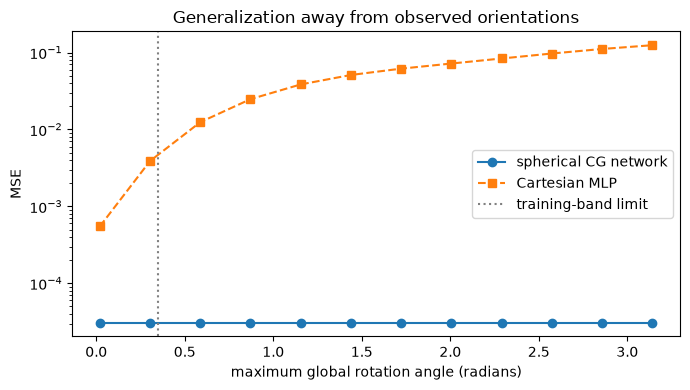

In [28]:
angles = np.linspace(0.02, np.pi, 12)
eq_mse, mlp_mse = [], []
for angle in angles:
    Ua, Va = dataset(200, np.random.default_rng(7), angle)
    Ya = target(Ua, Va)
    eq_mse.append(mse(net(theta, Ua, Va), Ya))
    mlp_mse.append(mse(mlp(np.hstack([Ua, Va])), Ya))

plt.figure(figsize=(7, 4))
plt.semilogy(angles, eq_mse, "o-", label="spherical CG network")
plt.semilogy(angles, mlp_mse, "s--", label="Cartesian MLP")
plt.axvline(0.35, color="gray", linestyle=":", label="training-band limit")
plt.xlabel("maximum global rotation angle (radians)")
plt.ylabel("MSE")
plt.title("Generalization away from observed orientations")
plt.legend()
plt.tight_layout()
plt.show()

## 5. A design worksheet for your physical system

In a new markdown cell, record:

1. Input quantities and their $\ell$ types.
2. Desired output and its $\ell$ type.
3. Other symmetries: translation, permutation, parity, time reversal, or exchange antisymmetry.
4. Hidden $\ell$ values and channel counts.
5. Candidate CG paths.
6. Safe nonlinearities.
7. Prediction and equivariance tests.

## Try it

1. Change the target to the torque `np.cross(U, V)`.
2. Add a scalar energy target `-np.sum(U*V, axis=1)`.
3. Evaluate on relative angles not represented in training, not merely new orientations.
4. Sketch how relative vectors, spherical harmonics, neighbor sums, and CG messages would enter a
   many-particle model.

## 6. Analytic Backpropagation for the Equivariant Spherical Model

Central finite differences requires 2 * 60 = 120 forward passes per gradient step (over 19,000 forward evaluations for 160 steps).
Below, we implement exact reverse-mode backpropagation through:
1. The unitary Cartesian <-> spherical projection (`sph_to_cart` / `cart_to_sph` adjoint).
2. The equivariant linear and Clebsch-Gordan tensor-product paths (`layer_backward`).
3. The invariant scalar tanh and gated vector/quadrupole non-linearities (`gate_backward`).


In [12]:
# Analytical Backpropagation Implementation for Equivariant Layer & Gate
def layer_forward_and_cache(params, features, mult_out, cgs=CG):
    """Forward pass through an equivariant layer, caching intermediate tensors."""
    batch = next(iter(features.values())).shape[0]
    out = {l: np.zeros((batch, channels, 2*l+1), dtype=complex) for l, channels in mult_out.items()}
    cache = {"features": features, "tp_products": {}}
    
    for key, weights in params.items():
        if key[0] == "lin":
            l = key[1]
            out[l] += np.einsum("oc,bcm->bom", weights, features[l])
        else:
            _, l1, l2, L = key
            C = cgs[(l1, l2, L)]
            products = np.einsum("Mij,bci,bdj->bcdM", C, features[l1], features[l2])
            products_flat = products.reshape(batch, -1, 2*L+1)
            cache["tp_products"][key] = (products, products_flat)
            out[L] += np.einsum("op,bpM->boM", weights, products_flat)
    return out, cache

def layer_backward(d_out, params, cache, mult_in, cgs=CG):
    """Backward pass through an equivariant layer."""
    features = cache["features"]
    d_features = {l: np.zeros_like(features[l], dtype=complex) for l in mult_in.keys()}
    grad_params = {}
    
    for key, weights in params.items():
        if key[0] == "lin":
            l = key[1]
            grad_params[key] = np.real(np.einsum("bom,bcm->oc", d_out[l], features[l].conj()))
            d_features[l] += np.einsum("oc,bom->bcm", weights, d_out[l])
        else:
            _, l1, l2, L = key
            C = cgs[(l1, l2, L)]
            products, products_flat = cache["tp_products"][key]
            grad_params[key] = np.real(np.einsum("boM,bpM->op", d_out[L], products_flat.conj()))
            
            d_products_flat = np.einsum("op,boM->bpM", weights, d_out[L])
            d_products = d_products_flat.reshape(products.shape)
            
            dx = np.einsum("bcdM,Mij,bdj->bci", d_products, C.conj(), features[l2].conj())
            dy = np.einsum("bcdM,Mij,bci->bdj", d_products, C.conj(), features[l1].conj())
            d_features[l1] += dx
            d_features[l2] += dy
            
    return d_features, grad_params

def gate_forward_and_cache(params, features, mult, use_norms=False):
    """Forward pass through symmetry-safe gates with caching for backpropagation."""
    scalars = features[0][:, :, 0].real
    b0_arg = features[0].real + params["b0"][None, :, None]
    scalar_output = np.tanh(b0_arg)
    gated = {0: scalar_output.astype(complex)}
    
    invariants = scalars
    gate_logits = np.einsum("oc,bc->bo", params["Wg"], invariants) + params["bg"]
    gates = np.tanh(gate_logits)
    
    offset = 0
    for l in sorted(mult):
        if l == 0:
            continue
        width = mult[l]
        block_gates = gates[:, offset:offset+width, None]
        gated[l] = features[l] * block_gates
        offset += width
        
    cache = {"features": features, "scalars": scalars, "scalar_output": scalar_output, "gates": gates}
    return gated, cache

def gate_backward(d_gated, params, cache, mult, use_norms=False):
    """Backward pass through symmetry-safe gates."""
    features = cache["features"]
    scalars = cache["scalars"]
    scalar_output = cache["scalar_output"]
    gates = cache["gates"]
    
    d_features = {}
    d_gates = np.zeros_like(gates)
    
    offset = 0
    for l in sorted(mult):
        if l == 0:
            continue
        width = mult[l]
        block_gates = gates[:, offset:offset+width, None]
        d_features[l] = d_gated[l] * block_gates
        d_gates[:, offset:offset+width] = np.real(np.sum(d_gated[l] * features[l].conj(), axis=2))
        offset += width
        
    d_gate_logits = d_gates * (1.0 - gates**2)
    grad_Wg = np.einsum("bo,bc->oc", d_gate_logits, scalars)
    grad_bg = np.sum(d_gate_logits, axis=0)
    d_scalars = np.einsum("bo,oc->bc", d_gate_logits, params["Wg"])
    
    d_scalar_output = np.real(d_gated[0])
    d_tanh_arg = d_scalar_output * (1.0 - scalar_output**2)
    grad_b0 = np.sum(d_tanh_arg[:, :, 0], axis=0)
    
    d_features[0] = np.zeros_like(features[0], dtype=complex)
    d_features[0][:, :, 0] = (d_tanh_arg[:, :, 0] + d_scalars).astype(complex)
    
    grad_params = {"b0": grad_b0, "Wg": grad_Wg, "bg": grad_bg}
    return d_features, grad_params

def backprop_grad(theta, U, V, Y, cgs=CG):
    """Compute analytical loss gradient with reverse-mode automatic differentiation."""
    first_params, gate_params, second_params = unflatten(theta, SPECS)
    batch = len(U)
    
    # Forward pass
    U_sph = cart_to_sph(U)
    V_sph = cart_to_sph(V)
    inputs = {1: np.stack([U_sph, V_sph], axis=1)}
    
    hidden_linear, cache1 = layer_forward_and_cache(first_params, inputs, M_HID, cgs)
    hidden, cache_gate = gate_forward_and_cache(gate_params, hidden_linear, M_HID)
    outputs, cache2 = layer_forward_and_cache(second_params, hidden, M_OUT, cgs)
    
    output_sph = outputs[1][:, 0]
    output_cart = sph_to_cart(output_sph)
    prediction = np.asarray(output_cart).real
    
    # Backward pass
    d_pred = (2.0 / (3.0 * batch)) * (prediction - Y)
    d_output_sph = cart_to_sph(d_pred)
    d_outputs = {1: d_output_sph[:, None, :]}
    
    d_hidden, grad_second = layer_backward(d_outputs, second_params, cache2, M_HID, cgs)
    d_hidden_linear, grad_gate = gate_backward(d_hidden, gate_params, cache_gate, M_HID)
    _, grad_first = layer_backward(d_hidden_linear, first_params, cache1, M_IN, cgs)
    
    return flatten([grad_first, grad_gate, grad_second])

def train_backprop(theta, U, V, Y, steps=160, lr=0.05):
    """Optimize the spherical CG network with Adam using analytical backpropagation."""
    first_moment = np.zeros_like(theta)
    second_moment = np.zeros_like(theta)
    
    print("Begin training ENN (Analytical Backpropagation)")
    for step in range(1, steps+1):
        gradient = backprop_grad(theta, U, V, Y)
        first_moment = 0.9 * first_moment + 0.1 * gradient
        second_moment = 0.999 * second_moment + 0.001 * gradient**2
        m_hat = first_moment / (1.0 - 0.9**step)
        v_hat = second_moment / (1.0 - 0.999**step)
        theta = theta - lr * m_hat / (np.sqrt(v_hat) + 1e-8)
        if step % 40 == 0:
            print(f"step {step:3d}: MSE {mse(net(theta, U, V), Y):.6f}")
    print("Finish training ENN (Analytical Backpropagation)")
    return theta


In [13]:
# 1. Gradient check: verify backpropagation against central finite differences
check_rng = np.random.default_rng(42)
U_chk, V_chk = dataset(10, check_rng, 0.35)
Y_chk = target(U_chk, V_chk)
theta_test = initial_theta.copy()

t0 = time.time()
g_bp = backprop_grad(theta_test, U_chk, V_chk, Y_chk)
t_bp = time.time() - t0

t0 = time.time()
g_fd = fd_grad(theta_test, U_chk, V_chk, Y_chk, h=1e-5)
t_fd = time.time() - t0

max_abs_diff = np.max(np.abs(g_bp - g_fd))
rel_err = max_abs_diff / (np.max(np.abs(g_bp)) + 1e-12)

print(f"Gradient check (10 samples, {len(theta_test)} parameters):")
print(f"  Backprop time:     {t_bp*1000:.2f} ms")
print(f"  Finite-diff time:  {t_fd*1000:.2f} ms ({t_fd/t_bp:.1f}x slower)")
print(f"  Max absolute diff: {max_abs_diff:.2e}")
print(f"  Relative error:    {rel_err:.2e}")


Gradient check (10 samples, 60 parameters):
  Backprop time:     5.64 ms
  Finite-diff time:  35.02 ms (6.2x slower)
  Max absolute diff: 2.96e-12
  Relative error:    7.29e-11


In [14]:
# 2. Train with analytic backpropagation on full training set and compare timing
t0 = time.time()
theta_bp = train_backprop(initial_theta.copy(), Utr, Vtr, Ytr, steps=160, lr=0.05)
bp_fit_seconds = time.time() - t0
eqerr_bp = equivariance_error(lambda U, V: net(theta_bp, U, V))

print(f"\n{'model':30s}{'train MSE':>12s}{'all-rotation MSE':>20s}{'equivariance':>16s}{'time (s)':>12s}")
print(f"{'ENN (Backpropagation)':30s}{mse(net(theta_bp,Utr,Vtr),Ytr):12.5f}{mse(net(theta_bp,Ute,Vte),Yte):20.5f}{eqerr_bp:16.1e}{bp_fit_seconds:12.2f}")
print(f"{'ENN (Finite differences)':30s}{mse(net(theta,Utr,Vtr),Ytr):12.5f}{mse(net(theta,Ute,Vte),Yte):20.5f}{eqerr:16.1e}{enn_fit_seconds:12.2f}")
print(f"{'Cartesian MLP':30s}{mse(mlp(Xtr),Ytr):12.5f}{mse(mlp(Xte),Yte):20.5f}{'--':>16s}{mlp_fit_seconds:12.2f}")
print(f"\nSpeedup: {enn_fit_seconds / bp_fit_seconds:.1f}x faster with analytic backpropagation!")


Begin training ENN (Analytical Backpropagation)
step  40: MSE 0.000247
step  80: MSE 0.000095
step 120: MSE 0.000058
step 160: MSE 0.000039
Finish training ENN (Analytical Backpropagation)

model                            train MSE    all-rotation MSE    equivariance    time (s)
ENN (Backpropagation)              0.00004             0.00004         5.8e-16        0.57
ENN (Finite differences)           0.00004             0.00004         3.9e-16       15.38
Cartesian MLP                      0.00333             0.11560              --        0.54

Speedup: 26.8x faster with analytic backpropagation!
